# ПР-7. Случайный лес и интерпретация важности признаков
Цель: сравнить одиночное дерево и случайный лес на задаче предсказания просрочки (default), подобрать параметры леса, сравнить три способа оценки важности признаков (встроенную, permutation importance, SHAP).

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score, average_precision_score, recall_score, f1_score

from src.transformers import CreditCleaner

df = pd.read_csv("../data/cs-training.csv", index_col=0)
df = df.rename(columns={
    "SeriousDlqin2yrs": "default",
    "RevolvingUtilizationOfUnsecuredLines": "utilization",
    "NumberOfTime30-59DaysPastDueNotWorse": "late_30_59",
    "DebtRatio": "debt_ratio",
    "MonthlyIncome": "income",
    "NumberOfOpenCreditLinesAndLoans": "open_credits",
    "NumberOfTimes90DaysLate": "late_90",
    "NumberRealEstateLoansOrLines": "real_estate",
    "NumberOfTime60-89DaysPastDueNotWorse": "late_60_89",
    "NumberOfDependents": "dependents",
})

X = df.drop(columns="default")
y = df["default"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(X_train.shape, X_test.shape)

c:\Users\user\.vscode\MLSU\credit-risk-ml\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


(120000, 10) (30000, 10)


In [2]:
prep = Pipeline([
    ("cleaner", CreditCleaner()),
    ("imputer", SimpleImputer(strategy="median")),
])

Xtr_arr = prep.fit_transform(X_train)          # обучается только на train
cols = prep.named_steps["cleaner"].transform(X_train.head(5)).columns.tolist()
Xtr = pd.DataFrame(Xtr_arr, columns=cols, index=X_train.index)
Xte = pd.DataFrame(prep.transform(X_test), columns=cols, index=X_test.index)

print(Xtr.shape, Xte.shape)
print(cols)

(120000, 12) (30000, 12)
['utilization', 'age', 'late_30_59', 'debt_ratio', 'income', 'open_credits', 'late_90', 'real_estate', 'late_60_89', 'dependents', 'total_late', 'income_missing']


In [3]:
def evaluate(model, name):
    model.fit(Xtr, y_train)
    p_tr = model.predict_proba(Xtr)[:, 1]
    p_te = model.predict_proba(Xte)[:, 1]
    return {
        "модель": name,
        "ROC-AUC train": roc_auc_score(y_train, p_tr),
        "ROC-AUC test": roc_auc_score(y_test, p_te),
        "PR-AUC test": average_precision_score(y_test, p_te),
    }

rows = [
    evaluate(DecisionTreeClassifier(random_state=42), "дерево (по умолчанию)"),
    evaluate(DecisionTreeClassifier(max_depth=5, min_samples_leaf=50, random_state=42), "дерево (глубина 5)"),
    evaluate(RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1), "лес (100 деревьев, по умолчанию)"),
]
pd.DataFrame(rows).set_index("модель").round(3)

,ROC-AUC train,ROC-AUC test,PR-AUC test
модель,,,
дерево (по умолчанию),1.000,0.611,0.121
дерево (глубина 5),0.849,0.848,0.358
"лес (100 деревьев, по умолчанию)",1.000,0.841,0.353


In [4]:
results = []
for depth in [None, 10]:
    for leaf in [1, 10, 50]:
        rf = RandomForestClassifier(n_estimators=100, max_depth=depth,
                                    min_samples_leaf=leaf, random_state=42, n_jobs=-1)
        score = cross_val_score(rf, Xtr, y_train, cv=3, scoring="roc_auc").mean()
        results.append({"max_depth": depth, "min_samples_leaf": leaf, "ROC-AUC (CV)": round(score, 4)})
        print(results[-1])

pd.DataFrame(results).sort_values("ROC-AUC (CV)", ascending=False)

{'max_depth': None, 'min_samples_leaf': 1, 'ROC-AUC (CV)': np.float64(0.8365)}
{'max_depth': None, 'min_samples_leaf': 10, 'ROC-AUC (CV)': np.float64(0.8583)}
{'max_depth': None, 'min_samples_leaf': 50, 'ROC-AUC (CV)': np.float64(0.8622)}
{'max_depth': 10, 'min_samples_leaf': 1, 'ROC-AUC (CV)': np.float64(0.8615)}
{'max_depth': 10, 'min_samples_leaf': 10, 'ROC-AUC (CV)': np.float64(0.8622)}
{'max_depth': 10, 'min_samples_leaf': 50, 'ROC-AUC (CV)': np.float64(0.8626)}


,max_depth,min_samples_leaf,ROC-AUC (CV)
5,10.0,50,0.8626
2,NaN,50,0.8622
4,10.0,10,0.8622
3,10.0,1,0.8615
1,NaN,10,0.8583
0,NaN,1,0.8365


## Одиночное дерево и случайный лес на одних и тех же данных
Все модели обучены на одной обучающей выборке (120 000 клиентов) и проверены на одной тестовой (30 000), предобработка из ПР-3 (пайплайн обучен только на train). Метрики: ROC-AUC и PR-AUC, потому что при доле просрочек 6,7% accuracy неинформативна.

- **Дерево без ограничений** полностью запомнило обучающие данные: ROC-AUC на train 1,000, на тесте только 0,611, PR-AUC 0,121 (случайное угадывание даёт PR-AUC около 0,067). Это классическое переобучение.
- **Дерево глубиной 5 (min_samples_leaf=50)** работает намного лучше: 0,849 на train и 0,848 на тесте.
- **Лес из 100 деревьев с параметрами по умолчанию** на тесте даёт 0,841: заметно лучше глубокого дерева, но не лучше ограниченного. Деревья в нём тоже растут до листьев из одного клиента и подстраиваются под шум, хотя усреднение сглаживает это. Значит, лес по умолчанию без настройки не гарантирует выигрыша.

In [5]:
BEST_DEPTH = 10
BEST_LEAF = 50

## Подбор гиперпараметров леса (3-кратная кросс-валидация на train, 100 деревьев)
| max_depth | min_samples_leaf | ROC-AUC (CV) |
|---|---|---|
| без ограничения | 1 | 0,8365 |
| без ограничения | 10 | 0,8583 |
| без ограничения | 50 | 0,8622 |
| 10 | 1 | 0,8615 |
| 10 | 10 | 0,8622 |
| 10 | 50 | 0,8626 |

Хуже всего лес без ограничений с листьями из одного клиента (0,8365): он переобучается. Любое ограничение (глубина 10 или минимум 50 клиентов в листе) поднимает качество до 0,862. Три лучшие комбинации различаются меньше чем на 0,0005, то есть практически равны. Выбраны max_depth=10 и min_samples_leaf=50 (лучший результат, и модель при этом проще). Ограничение: сетка небольшая (6 вариантов), параметр max_features не подбирался. Выбор сделан по кросс-валидации на train, тестовая выборка не использовалась.

c:\Users\user\.vscode\MLSU\credit-risk-ml\venv\Lib\site-packages\sklearn\ensemble\_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


25 0.8608
50 0.8621
100 0.8625
200 0.8628
300 0.8629


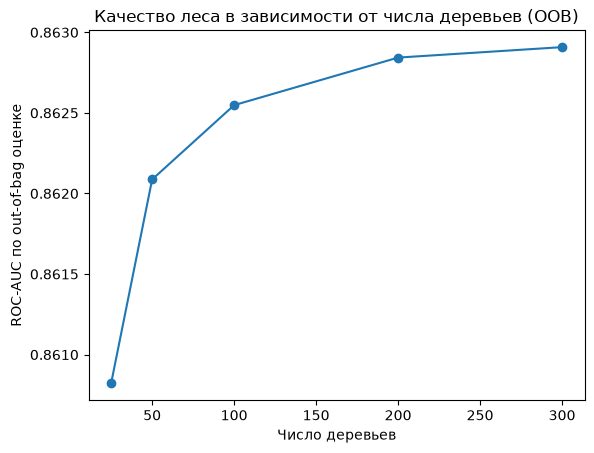

In [6]:
sizes = [25, 50, 100, 200, 300]
oob_auc = []
for n in sizes:
    rf = RandomForestClassifier(n_estimators=n, max_depth=BEST_DEPTH,
                                min_samples_leaf=BEST_LEAF, oob_score=True,
                                random_state=42, n_jobs=-1).fit(Xtr, y_train)
    proba = rf.oob_decision_function_[:, 1]
    mask = ~np.isnan(proba)
    oob_auc.append(roc_auc_score(y_train[mask], proba[mask]))
    print(n, round(oob_auc[-1], 4))

plt.plot(sizes, oob_auc, marker="o")
plt.title("Качество леса в зависимости от числа деревьев (OOB)")
plt.xlabel("Число деревьев")
plt.ylabel("ROC-AUC по out-of-bag оценке")
plt.show()

In [7]:
N_TREES = 300

## Выбор числа деревьев (out-of-bag оценка)
Каждое дерево не видит примерно треть клиентов, и на них можно проверять лес, не трогая тест. ROC-AUC по OOB: 25 деревьев — 0,8608; 50 — 0,8621; 100 — 0,8625; 200 — 0,8628; 300 — 0,8629.

Качество быстро растёт до 100 деревьев, дальше выходит на плато: от 200 до 300 прирост всего 0,0001. Выбрано 300 деревьев. Строго говоря, 200 дали бы почти то же самое, но в лесу больше деревьев не приводит к переобучению, а только замедляет обучение, поэтому 300 взято с запасом. Предупреждение sklearn о нехватке OOB-оценок при 25 деревьях ожидаемо: при малом числе деревьев часть клиентов попадает в обучение каждого дерева, и для них оценки нет (такие строки исключены из расчёта).

ROC-AUC test: 0.867
PR-AUC test:  0.398
Recall (порог 0,5): 0.152  F1: 0.244


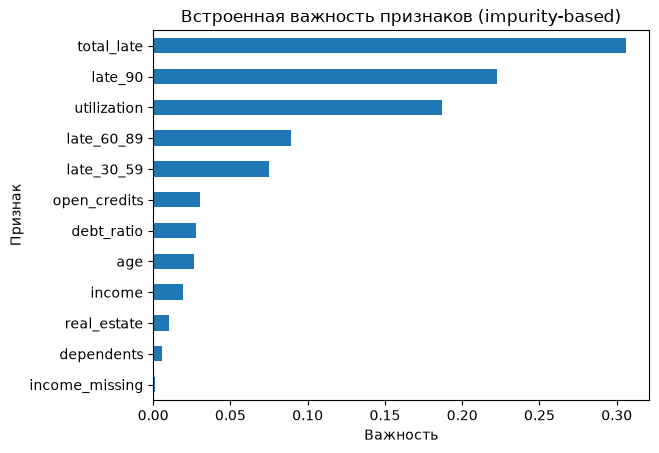

In [8]:
rf = RandomForestClassifier(n_estimators=N_TREES, max_depth=BEST_DEPTH,
                            min_samples_leaf=BEST_LEAF, random_state=42, n_jobs=-1)
rf.fit(Xtr, y_train)

p_te = rf.predict_proba(Xte)[:, 1]
pred = (p_te >= 0.5).astype(int)
print("ROC-AUC test:", round(roc_auc_score(y_test, p_te), 3))
print("PR-AUC test: ", round(average_precision_score(y_test, p_te), 3))
print("Recall (порог 0,5):", round(recall_score(y_test, pred), 3), " F1:", round(f1_score(y_test, pred), 3))

imp_builtin = pd.Series(rf.feature_importances_, index=cols).sort_values()
imp_builtin.plot(kind="barh")
plt.title("Встроенная важность признаков (impurity-based)")
plt.xlabel("Важность")
plt.ylabel("Признак")
plt.show()

In [9]:
pd.DataFrame(rows + [{
    "модель": f"лес ({N_TREES} деревьев, настроенный)",
    "ROC-AUC train": roc_auc_score(y_train, rf.predict_proba(Xtr)[:, 1]),
    "ROC-AUC test": roc_auc_score(y_test, p_te),
    "PR-AUC test": average_precision_score(y_test, p_te),
}]).set_index("модель").round(3)

,ROC-AUC train,ROC-AUC test,PR-AUC test
модель,,,
дерево (по умолчанию),1.000,0.611,0.121
дерево (глубина 5),0.849,0.848,0.358
"лес (100 деревьев, по умолчанию)",1.000,0.841,0.353
"лес (300 деревьев, настроенный)",0.876,0.867,0.398


## Итоговый лес и сравнение с деревом
| Модель | ROC-AUC train | ROC-AUC test | PR-AUC test |
|---|---|---|---|
| дерево (по умолчанию) | 1,000 | 0,611 | 0,121 |
| дерево (глубина 5) | 0,849 | 0,848 | 0,358 |
| лес (100 деревьев, по умолчанию) | 1,000 | 0,841 | 0,353 |
| лес (300 деревьев, настроенный) | 0,876 | 0,867 | 0,398 |

Настроенный лес лучший: он превосходит дерево по умолчанию на 0,256 ROC-AUC и дерево глубиной 5 на 0,019 ROC-AUC и 0,040 PR-AUC, а разрыв между train и test составляет всего 0,009. Для сравнения, логистическая регрессия из ПР-5 с class_weight на том же тесте давала ROC-AUC 0,860 и PR-AUC 0,386, то есть лес лучше, но ненамного (оценка по одной тестовой выборке).

При пороге 0,5 лес находит только 15,2% должников (recall 0,152, F1 0,244). Это не недостаток способности отличать клиентов (AUC высокий), а следствие того, что лес обучался без коррекции дисбаланса и редко выдаёт вероятность выше 0,5. Для практического использования порог нужно снижать или использовать class_weight, как в ПР-5.

In [10]:
perm = permutation_importance(rf, Xte, y_test, scoring="roc_auc",
                              n_repeats=5, random_state=42, n_jobs=-1)
imp_perm = pd.Series(perm.importances_mean, index=cols)

compare = pd.DataFrame({
    "встроенная": rf.feature_importances_,
    "permutation": imp_perm,
}, index=cols)
compare["место (встроенная)"] = compare["встроенная"].rank(ascending=False).astype(int)
compare["место (permutation)"] = compare["permutation"].rank(ascending=False).astype(int)
compare.sort_values("место (permutation)").round(4)

,встроенная,permutation,место (встроенная),место (permutation)
utilization,0.1868,0.0615,3,1
total_late,0.3057,0.0353,1,2
late_90,0.2228,0.0126,2,3
age,0.0264,0.0075,8,4
open_credits,0.0300,0.0050,6,5
late_60_89,0.0892,0.0047,4,6
late_30_59,0.0747,0.0045,5,7
debt_ratio,0.0280,0.0032,7,8
real_estate,0.0102,0.0014,10,9
income,0.0195,0.0013,9,10


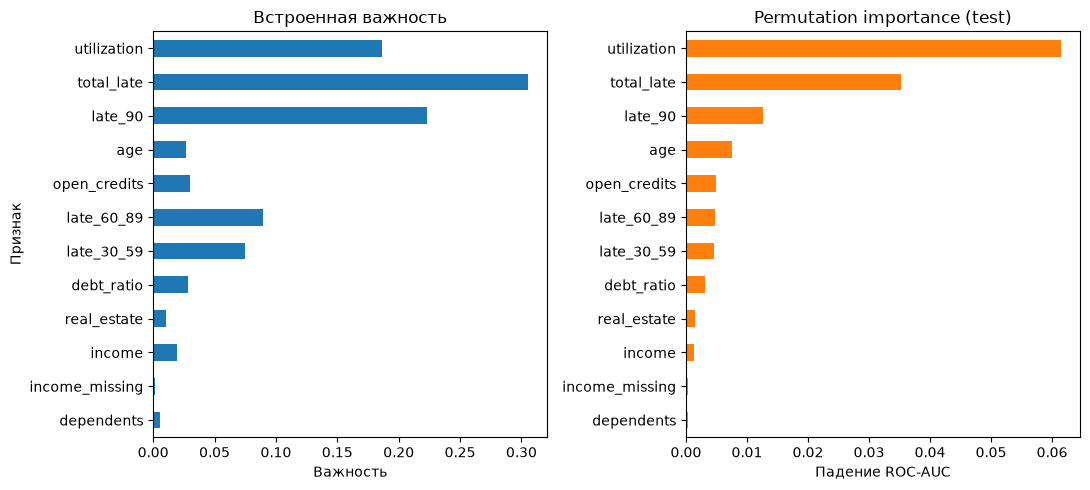

In [11]:
order = compare.sort_values("permutation").index
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
compare.loc[order, "встроенная"].plot(kind="barh", ax=axes[0])
axes[0].set_title("Встроенная важность")
axes[0].set_xlabel("Важность")
axes[0].set_ylabel("Признак")
compare.loc[order, "permutation"].plot(kind="barh", ax=axes[1], color="tab:orange")
axes[1].set_title("Permutation importance (test)")
axes[1].set_xlabel("Падение ROC-AUC")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

## Встроенная важность и permutation importance
| Признак | Встроенная | Место | Permutation (падение ROC-AUC) | Место |
|---|---|---|---|---|
| utilization | 0,187 | 3 | 0,0615 | 1 |
| total_late | 0,306 | 1 | 0,0353 | 2 |
| late_90 | 0,223 | 2 | 0,0126 | 3 |
| age | 0,026 | 8 | 0,0075 | 4 |
| open_credits | 0,030 | 6 | 0,0050 | 5 |
| late_60_89 | 0,089 | 4 | 0,0047 | 6 |
| late_30_59 | 0,075 | 5 | 0,0045 | 7 |
| debt_ratio | 0,028 | 7 | 0,0032 | 8 |
| real_estate | 0,010 | 10 | 0,0014 | 9 |
| income | 0,0195 | 9 | 0,0013 | 10 |
| income_missing | 0,0014 | 12 | 0,0004 | 11 |
| dependents | 0,0055 | 11 | 0,0003 | 12 |

**Что совпадает.** В верхней тройке оба метода называют одни и те же признаки (utilization, total_late, late_90), а в хвосте одни и те же четыре (real_estate, income, income_missing, dependents).
**Что расходится.** Встроенная важность ставит на первое место total_late, а permutation — utilization (падение AUC 0,0615 против 0,0353 у total_late). Признаки late_60_89 и late_30_59 по встроенной важности на 4–5 местах, по permutation на 6–7. Возраст поднимается с 8 места на 4. Причины расхождения объяснены ниже, в отдельном разделе.

In [12]:
rng = np.random.RandomState(0)
Xtr_n = Xtr.copy(); Xte_n = Xte.copy()
Xtr_n["noise"] = rng.rand(len(Xtr_n))
Xte_n["noise"] = rng.rand(len(Xte_n))

rf_n = RandomForestClassifier(n_estimators=N_TREES, max_depth=BEST_DEPTH,
                              min_samples_leaf=BEST_LEAF, random_state=42, n_jobs=-1).fit(Xtr_n, y_train)
perm_n = permutation_importance(rf_n, Xte_n, y_test, scoring="roc_auc",
                                n_repeats=5, random_state=42, n_jobs=-1)

noise_res = pd.DataFrame({
    "встроенная": rf_n.feature_importances_,
    "permutation": perm_n.importances_mean,
}, index=Xtr_n.columns)
noise_res["место (встроенная)"] = noise_res["встроенная"].rank(ascending=False).astype(int)
noise_res["место (permutation)"] = noise_res["permutation"].rank(ascending=False).astype(int)
noise_res.loc[["noise"]].round(4)

,встроенная,permutation,место (встроенная),место (permutation)
noise,0.0152,0.0001,10,13


## Эксперимент: случайный признак
К признакам добавлен столбец из случайных чисел (noise), который заведомо не несёт информации, и лес обучен заново.

| Метод | Важность noise | Место из 13 |
|---|---|---|
| встроенная | 0,0152 | 10 |
| permutation | 0,0001 | 13 (последнее) |

Встроенная важность дала случайному шуму заметное значение (0,0152) и 10-е место: он обогнал три реальных признака (судя по основной таблице, вероятно real_estate, dependents и income_missing) и почти сравнялся с income (0,0195). Permutation importance оценила шум практически нулём и поставила последним. Это подтверждает известный недостаток встроенной важности: непрерывные признаки с большим числом уникальных значений получают завышенную важность, потому что у дерева больше вариантов разбиения, из которых оно может выбрать случайно удачное. Практический вывод: признаки со встроенной важностью на уровне шума (около 0,015 и ниже) нельзя считать надёжно полезными. Ограничение: эксперимент выполнен с одним случайным столбцом, для надёжности его стоило бы повторить с несколькими.

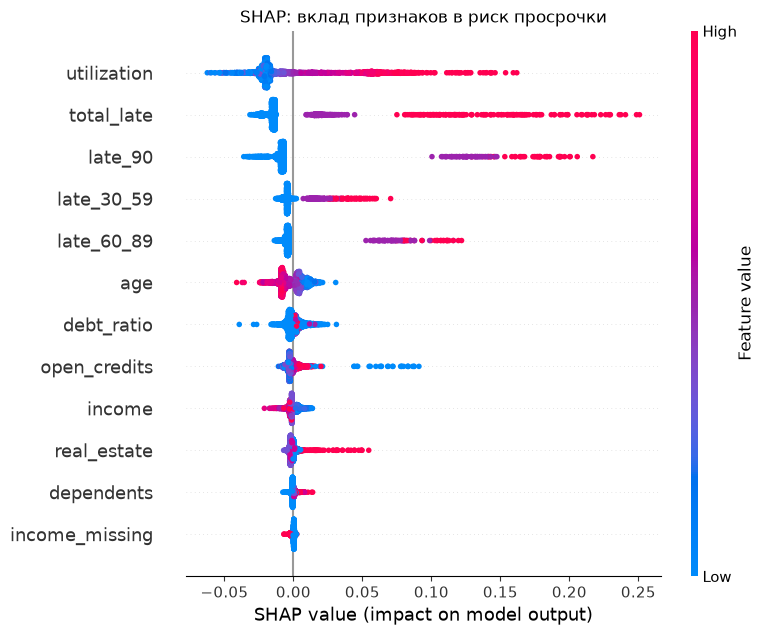

In [13]:
Xs = Xte.sample(2000, random_state=42)
ys = y_test.loc[Xs.index]

explainer = shap.TreeExplainer(rf)
sv = explainer.shap_values(Xs)

# в разных версиях shap формат ответа разный, приводим к классу «просрочка» (1)
if isinstance(sv, list):
    sv1 = sv[1]
elif np.ndim(sv) == 3:
    sv1 = sv[:, :, 1]
else:
    sv1 = sv

ev = explainer.expected_value
base = float(np.ravel(ev)[-1])

shap.summary_plot(sv1, Xs, show=False)
plt.title("SHAP: вклад признаков в риск просрочки")
plt.show()

## SHAP: общая картина (2 000 случайных клиентов тестовой выборки)
Каждая точка на графике — клиент. Положение по горизонтали — вклад признака в предсказанную вероятность просрочки (в единицах вероятности; вправо — риск растёт, влево — снижается), цвет — значение признака (красный — большое, синий — малое).

- **utilization:** высокие значения (красные точки) повышают риск до +0,16, низкие слегка снижают (около −0,02).
- **late_90, total_late, late_30_59, late_60_89:** эффект ступенчатый. Точки разделены на две группы: при отсутствии просрочек вклад чуть ниже нуля (около −0,01), при наличии хотя бы одной вклад сразу положительный (для late_90 от +0,10 до +0,22, для total_late до +0,25).
- **age:** старший возраст (красные точки) снижает риск, молодой слегка повышает. Это согласуется с ПР-2, где доля просрочек падала с возрастом.
- **open_credits:** правый «хвост» образуют синие точки, то есть очень малое число открытых кредитов слегка повышает оценку риска (интерпретировать осторожно, таких клиентов немного).
- **dependents, income_missing, income:** вклад близок к нулю.

Должник, которого модель уверенно нашла | вероятность просрочки: 0.755


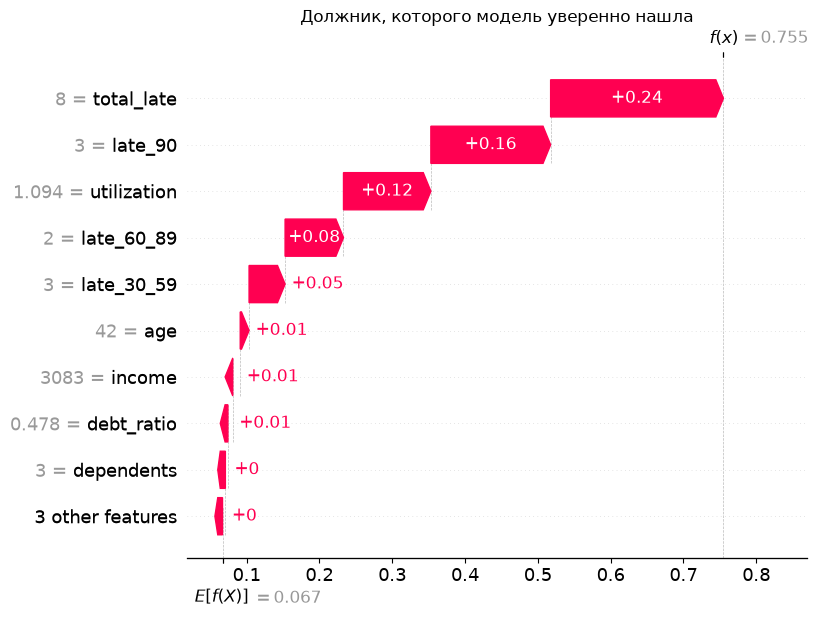

Хороший клиент, низкий риск | вероятность просрочки: 0.005


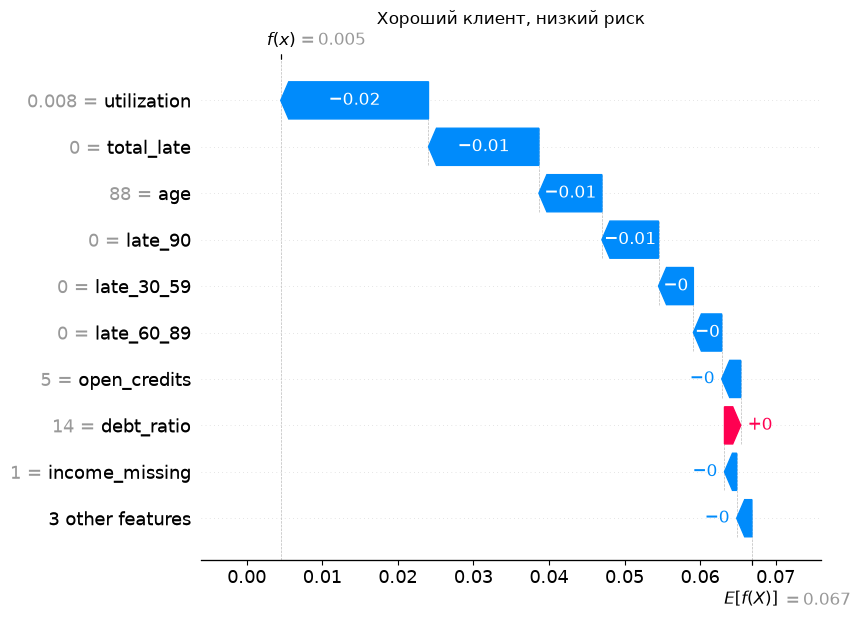

Должник, которого модель пропустила | вероятность просрочки: 0.005


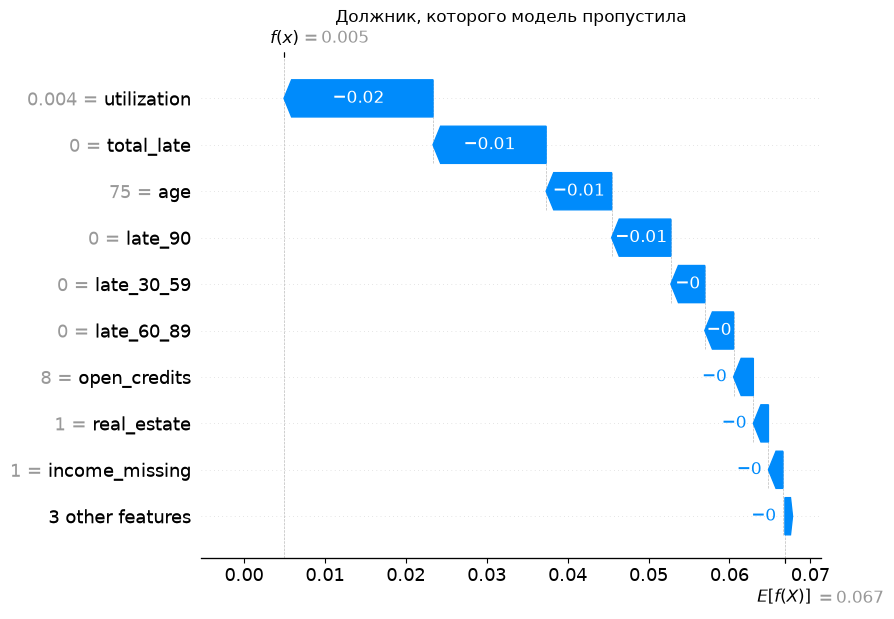

In [14]:
proba_s = rf.predict_proba(Xs)[:, 1]
pos = np.where(ys.values == 1)[0]
neg = np.where(ys.values == 0)[0]

picks = {
    "Должник, которого модель уверенно нашла": pos[np.argmax(proba_s[pos])],
    "Хороший клиент, низкий риск": neg[np.argmin(proba_s[neg])],
    "Должник, которого модель пропустила": pos[np.argmin(proba_s[pos])],
}

for title, i in picks.items():
    print(title, "| вероятность просрочки:", round(proba_s[i], 3))
    shap.plots.waterfall(
        shap.Explanation(values=sv1[i], base_values=base,
                         data=Xs.iloc[i].values, feature_names=cols),
        show=False)
    plt.title(title)
    plt.show()

## SHAP: три конкретных клиента
Базовое значение (средняя вероятность просрочки по выборке) равно 0,067. Каждый признак сдвигает ответ модели вверх или вниз от него.

**1. Должник, которого модель уверенно нашла (вероятность 0,755, в 11 раз выше среднего).** Основной вклад дали признаки просрочек: total_late = 8 (+0,24), late_90 = 3 (+0,16), late_60_89 = 2 (+0,08), late_30_59 = 3 (+0,05) (total_late = 3 + 2 + 3 = 8, что подтверждает корректность составного признака), а также использование лимита utilization = 1,094 (+0,12). Значение 1,094 — это граница обрезки выбросов из нашего трансформера CreditCleaner, то есть реальное значение у клиента было не меньше. Возраст, доход и долговая нагрузка добавили по +0,01.

**2. Хороший клиент (вероятность 0,005).** Все факторы снижают риск: utilization = 0,008 (−0,02), просрочек нет (total_late и late_90 по −0,01), возраст 88 лет (−0,01). Долговая нагрузка 14 на ответ не повлияла.

**3. Должник, которого модель пропустила (вероятность 0,005).** Этот клиент выбран как самый показательный промах из выборки в 2 000 человек, поэтому он нетипичен. Его профиль почти не отличается от клиента 2: utilization = 0,004 (−0,02), просрочек нет, возраст 75 лет. Все признаки говорят «надёжный клиент», но долг он не вернул. Модель по этим данным его найти не могла: причины, вызвавшие просрочку (например, потеря работы), в признаках отсутствуют. Это граница возможностей данных, а не ошибка настройки.

## Почему встроенная важность и permutation importance расходятся, и что показывает SHAP
**Расхождение из-за коррелирующих признаков.** Признаки просрочек дублируют друг друга: total_late равен сумме late_30_59, late_60_89 и late_90, а сами они коррелируют между собой (0,22–0,31 по ПР-2).
- Встроенная важность считается при обучении по тому, насколько признак улучшает разбиения в деревьях. Из почти одинаковых признаков деревья берут то один, то другой, и «заслуга» делится между ними. Поэтому на графике все четыре стоят наверху, и вместе они дают около 0,69 от всей важности (0,306 + 0,223 + 0,089 + 0,075).
- Permutation importance перемешивает один признак на тесте и смотрит на падение качества. Если та же информация есть в соседних столбцах, модель берёт её оттуда, и падение мало. Поэтому late_90, второй по встроенной важности (0,223), получил всего 0,0126. А utilization дубликатов не имеет, его перемешивание теряет уникальную информацию, и он занял первое место. Значит, по permutation важность коррелирующих признаков занижена, и оценивать группу просрочек нужно целиком.
- Встроенная важность также завышает признаки с большим числом уникальных значений (показано экспериментом со случайным столбцом). На наших реальных признаках этот эффект перекрыт эффектом корреляции.

**Что показывает SHAP, чего не показывают первые два метода.**
1. Направление: utilization выше — риск выше, возраст выше — риск ниже. Встроенная важность и permutation дают только величину значимости.
2. Объяснение для одного клиента: какие признаки и насколько подняли или снизили его оценку (три примера выше).
3. Форму зависимости: например, у late_90 эффект ступенчатый (нет просрочки: около −0,01, есть хотя бы одна: от +0,10 до +0,22), что не видно из одного числа важности.
4. Вклады складываются в ответ: базовая вероятность 0,067 плюс вклады признаков равна предсказанию модели.

**Важность не равна причинности.** Все три метода объясняют, как модель использует признаки, а не что вызывает просрочку. Кроме того, как отмечалось в ПР-2, период расчёта признаков просрочек в описании датасета не указан. Если он пересекается с периодом целевой переменной, их высокая важность может частично быть следствием утечки.

## Выводы
**1. Дерево и лес.** Одиночное дерево без ограничений переобучается (AUC 1,000 на train и 0,611 на тесте). Настроенный лес из 300 деревьев лучший: ROC-AUC 0,867 и PR-AUC 0,398 на тесте при разрыве с train 0,009. Лес по умолчанию (0,841) не лучше дерева глубиной 5 (0,848): настройка параметров важнее выбора «леса вместо дерева».
**2. Параметры и число деревьев.** Лучшие параметры по кросс-валидации: max_depth=10, min_samples_leaf=50. Качество по OOB выходит на плато около 200 деревьев, выбрано 300 с запасом.
**3. Важность признаков.** Наиболее значимы признаки просрочек и использование кредитного лимита (utilization). Наименее значимы dependents и income_missing: по обоим методам их важность на уровне случайного шума, поэтому они кандидаты на исключение (эксперимент по удалению в этой работе не проводился).
**4. Сравнение методов.** Встроенная важность и permutation расходятся из-за коррелирующих признаков просрочек и склонности встроенной важности завышать признаки с большим числом значений (случайный шум получил встроенную важность 0,0152 и 10-е место, по permutation 0,0001 и последнее). SHAP добавляет направление эффектов и объяснение для отдельных клиентов.
**5. Ограничения.** Оценка по одной тестовой выборке; recall при пороге 0,5 низкий (0,152), порог не настраивался; эксперимент с шумом выполнен с одним случайным столбцом; важность не доказывает причинность, и существует риск утечки через признаки просрочек.